## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Lawson Pham

**Date:** 10/10/2026

**Q1**

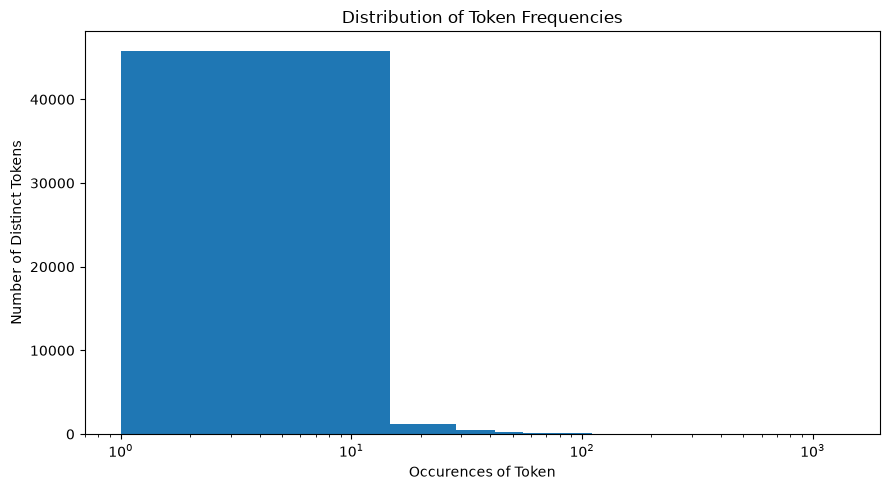

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.figure(figsize=(9,5))
plt.hist(token_count.values(), bins=100)
plt.xscale("log")
plt.xlabel("Occurences of Token")
plt.ylabel("Number of Distinct Tokens")
plt.title("Distribution of Token Frequencies")
plt.tight_layout()
plt.show()

I noticed that the token frequency has a long tail, where most distinct tokens show up a small amount of time, while there are some tokens that show up more frequently. It is right skewed, with the concentration of tokens having not a lot of occurences.

**Q2**

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

df = pd.read_parquet("data/Phishing_clean.parquet")
y = df["Email Type"]
X = df.drop(columns="Email Type")

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Token regression")
print(f"Training R^2: {linear_model.score(X_train, y_train):.4f}")
print(f"Testing R^2: {linear_model.score(X_test, y_test):.4f}")

# largest coefficients
coef = pd.Series(linear_model.coef_, index=X.columns)
print("\nLargest coefficients by absolute value:")
print(coef.reindex(coef.abs().sort_values(ascending=False).head(15).index))


Token regression
Training R^2: 0.7713
Testing R^2: 0.6424

Largest coefficients by absolute value:
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#331f30;             0.615728
#000000;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
cnet                -0.503287
zdnet               -0.449120
para                 0.415604
fax,                 0.407003
exercise!            0.402741
dtype: float64


R^2 on training set is 0.7713. R^2 on test set is 0.6424. The top three words with the largest coefficients is background-image:, localized, and thermal, with the rest of the list shown above.

**Q3**

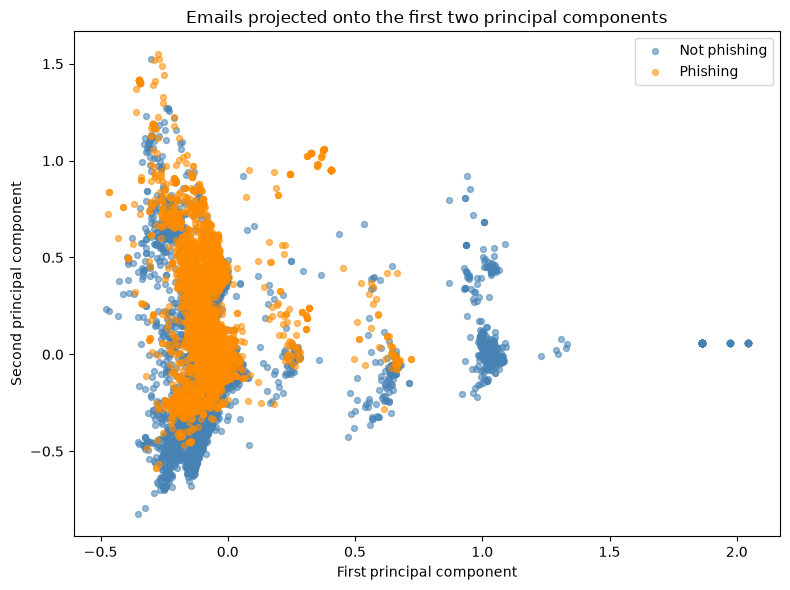

In [ ]:
from sklearn.decomposition import PCA

pca_tokens = PCA(n_components=2).fit(X)
X_pca_tokens = pca_tokens.transform(X)

plt.figure(figsize=(8, 6))
for label, name, color in [(0, "Not phishing", "steelblue"), (1, "Phishing", "darkorange")]:
    mask = y.to_numpy() == label
    plt.scatter(
        X_pca_tokens[mask, 0], X_pca_tokens[mask, 1],
        label=name, color=color, alpha=0.55, s=18
    )
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("Emails projected onto the first two principal components")
plt.legend()
plt.tight_layout()
plt.show()

I noticed that for the phishing emails, they overlap with most of the not phishing emails, signifying that they try to make the phishing emails looks as realistic as possible, so that there is no apparent separation or pattern that can distinct the difference between them.

**Q4**

In [27]:
n_components = 2610

pca_2610 = PCA(n_components=n_components, svd_solver="full")
X_train_pc = pca_2610.fit_transform(X_train)
X_test_pc = pca_2610.transform(X_test)

pc_model = LinearRegression()
pc_model.fit(X_train_pc, y_train)

print("\nRegression using first 2,610 principal components")
print(f"Training R^2: {pc_model.score(X_train_pc, y_train):.4f}")
print(f"Test R^2: {pc_model.score(X_test_pc, y_test):.4f}")


Regression using first 2,610 principal components
Training R^2: 0.7707
Test R^2: 0.6450


R^2 for training set is 0.7707. R^2 for testing set is 0.6450. Compared to normal regression, it is around the same values, comparing 0.7713 to 0.7707 for training and 0.6424 to 0.6450 for test.

**Q5**

The advantage of using principal components to run the regression instead of the whole data set is that it uses a smaller set of variables, that combine unnecessary values that make the regression easier to compute while keeping similar variation values. It helps with removing the bulk of token variables that are uncorrelated while keeping the value around the same.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ea495f69f6a262e42e0b21b75ea17ca442e0f144
- **AI tool and model used:** ChatGPT 5.6 Luna

### *Prompts used

1. How can I improve my code and make sure it is correct.

### *AI-proposed changes


1. Improve the histogram: Use logarithmically spaced bins rather than only setting the x-axis to logarithmic scale. This makes the heavily right-skewed token frequency distribution easier to interpret. Correct the spelling of "Occurrences" in the axis label.

2. Improve coefficient analysis: Keep the reproducible 80/20 train-test split with random_state=42 and stratify=y. Display the largest positive and negative coefficients separately to distinguish tokens associated with phishing from tokens associated with legitimate emails.

3. Prevent data leakage: Fit PCA using only the training data and then transform the training and test data. Combine their transformed coordinates for visualization if you want to display all emails. Report the explained variance ratios of the first two principal components.

4. Improve interpretation: Avoid concluding that phishing emails deliberately imitate legitimate emails based solely on overlapping PCA points. The plot only establishes that the first two principal components do not clearly separate the two classes.

5. Verify PCA dimensionality: Check that 2,610 components do not exceed the maximum allowed by the training data dimensions. Continue fitting PCA on training data only and transforming test data using that fitted PCA.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I accept as it will help with visualizing the data and making it easier to interpret. |
| 2 | reject | I followed the instructions of the assignment and this is not what the assignment tells me to do. |
| 3 | reject | This is not what the assignment tells me to do, it tells me that what I have is already correct and this was just a recommendation. |
| 4 | Accept | This will make sure my answer is correct and I am not assuming anything that is wrong about the data. |
| 5 | reject | It already does not exceed the maximum allowed. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**Q1**

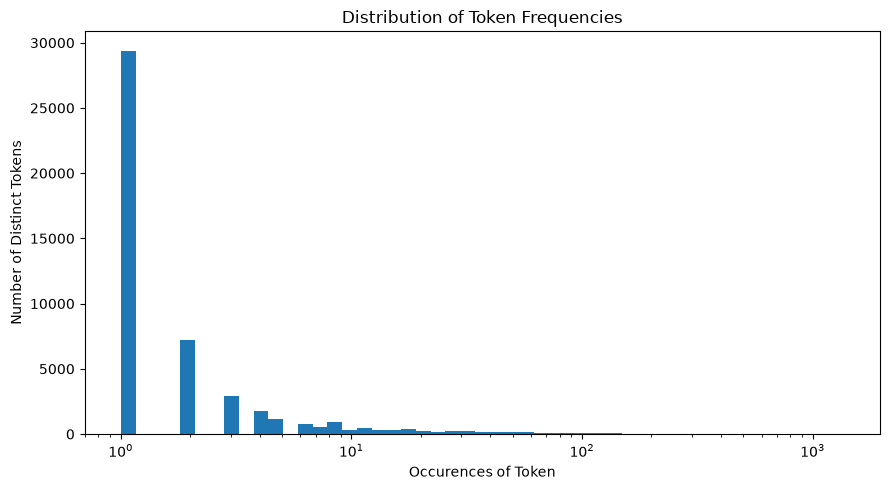

In [4]:
# Your Phase 2 solution to the problem goes here.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


frequencies = np.array(list(token_count.values()))

bins = np.logspace(
    np.log10(frequencies.min()),
    np.log10(frequencies.max()),
    50
)

plt.figure(figsize=(9,5))
plt.hist(token_count.values(), bins=bins)
plt.xscale("log")
plt.xlabel("Occurences of Token")
plt.ylabel("Number of Distinct Tokens")
plt.title("Distribution of Token Frequencies")
plt.tight_layout()
plt.show()

I noticed that the token frequency has a long tail, where most distinct tokens show up a small amount of time, while there are some tokens that show up more frequently. It is right skewed, with the concentration of tokens having not a lot of occurences.

**Q2**

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

df = pd.read_parquet("data/Phishing_clean.parquet")
y = df["Email Type"]
X = df.drop(columns="Email Type")

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Token regression")
print(f"Training R^2: {linear_model.score(X_train, y_train):.4f}")
print(f"Testing R^2: {linear_model.score(X_test, y_test):.4f}")

# largest coefficients
coef = pd.Series(linear_model.coef_, index=X.columns)
print("\nLargest coefficients by absolute value:")
print(coef.reindex(coef.abs().sort_values(ascending=False).head(15).index))


Token regression
Training R^2: 0.7713
Testing R^2: 0.6424

Largest coefficients by absolute value:
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#331f30;             0.615728
#000000;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
cnet                -0.503287
zdnet               -0.449120
para                 0.415604
fax,                 0.407003
exercise!            0.402741
dtype: float64


R^2 on training set is 0.7713. R^2 on test set is 0.6424. The top three words with the largest coefficients is background-image:, localized, and thermal, with the rest of the list shown above.

**Q3**

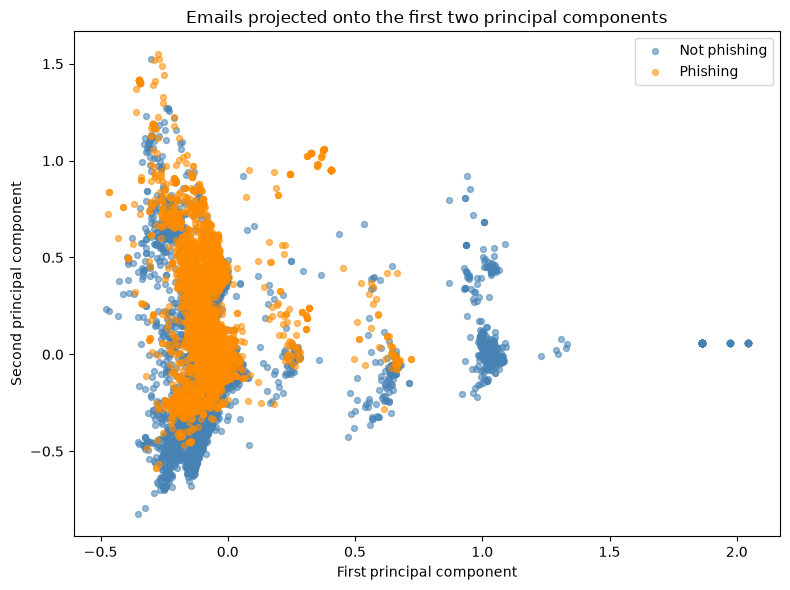

In [ ]:
from sklearn.decomposition import PCA

pca_tokens = PCA(n_components=2).fit(X)
X_pca_tokens = pca_tokens.transform(X)

plt.figure(figsize=(8, 6))
for label, name, color in [(0, "Not phishing", "steelblue"), (1, "Phishing", "darkorange")]:
    mask = y.to_numpy() == label
    plt.scatter(
        X_pca_tokens[mask, 0], X_pca_tokens[mask, 1],
        label=name, color=color, alpha=0.55, s=18
    )
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("Emails projected onto the first two principal components")
plt.legend()
plt.tight_layout()
plt.show()

I noticed that for the phishing emails, they overlap with most of the not phishing emails, so that there is no apparent separation or pattern that can distinct the difference between them.

**Q4**

In [ ]:
n_components = 2610

pca_2610 = PCA(n_components=n_components, svd_solver="full")
X_train_pc = pca_2610.fit_transform(X_train)
X_test_pc = pca_2610.transform(X_test)

pc_model = LinearRegression()
pc_model.fit(X_train_pc, y_train)

print("\nRegression using first 2,610 principal components")
print(f"Training R^2: {pc_model.score(X_train_pc, y_train):.4f}")
print(f"Test R^2: {pc_model.score(X_test_pc, y_test):.4f}")


Regression using first 2,610 principal components
Training R^2: 0.7707
Test R^2: 0.6450


R^2 for training set is 0.7707. R^2 for testing set is 0.6450. Compared to normal regression, it is around the same values, comparing 0.7713 to 0.7707 for training and 0.6424 to 0.6450 for test.

**Q5**

The advantage of using principal components to run the regression instead of the whole data set is that it uses a smaller set of variables, that combine unnecessary values that make the regression easier to compute while keeping similar variation values. It helps with removing the bulk of token variables that are uncorrelated while keeping the value around the same.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]
The main improvements of AI assistance includes helping with visualization of the histogram and making sure that my answers are not assuming, but are according to what is seen in the graphs. The addition of using log bins helped with visualization a lot and making sure that I was not assuming that phishing emails were made to be realistic, but that there is no apparently difference in pattern between phishing and not phishing helps with talking about data. AI mistakes is giving me recommendations that will change the code so that it would not fit under the instructions, such as with the PCA and adding max and min for coefficient values. When looking in depth, it tells me that my answers are already correct and that is something that I should add optionally, which it first makes it look like I did it wrong. The final solution was verified by running all the cells and comparing it to phase 1 results, getting the same results and same skew for the graphs.